# Project :- loan Approval

# Summary :- 

`What i gonna done here ?`

# Import libraries 

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import plotly as pl

# Train/Test Split
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
# Preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

# Load the dataset

In [6]:
df = pd.read_csv('/Users/shyamalkar/Desktop/ML_project/Loan_Prediction/train_u6lujuX_CVtuZ9i (1).csv') # load the dataset 

# Understand the dataset

In [7]:
df.head() # first 5 columns

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [8]:
df.tail() # last 5 columns

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


In [9]:
df.describe() # full data explain 

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [10]:
df.info() # information about the data

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


In [11]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [12]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [13]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')

# EDA

# Target Variable - Loan Status 

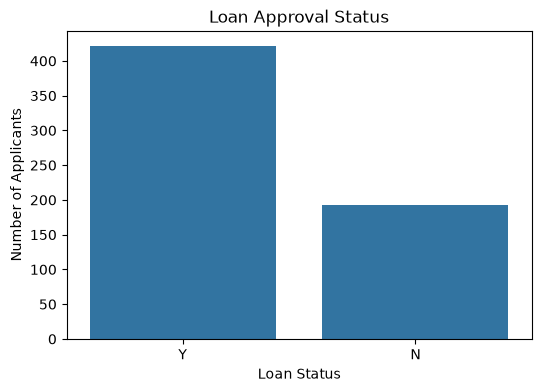

In [14]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Loan_Status")

plt.title("Loan Approval Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")

plt.show()

# Categorical Feature analysis 

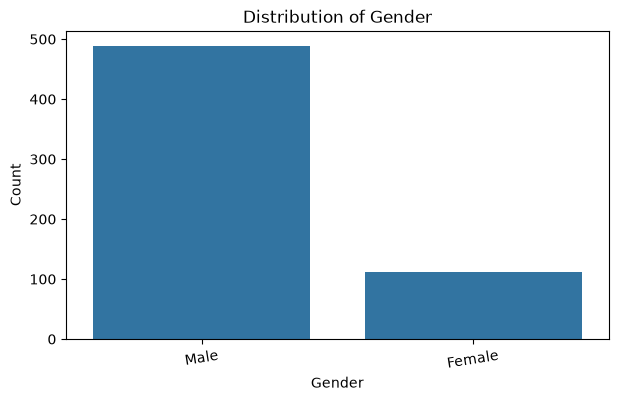

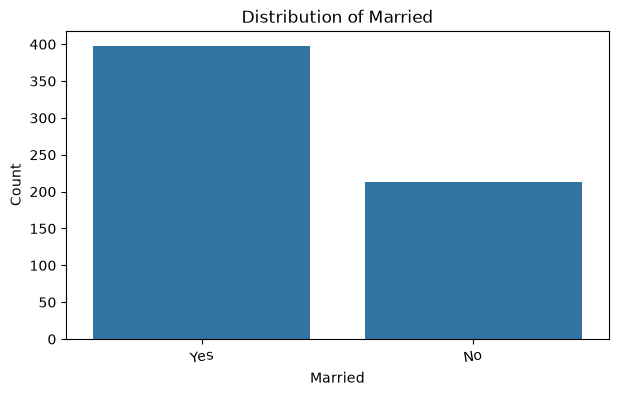

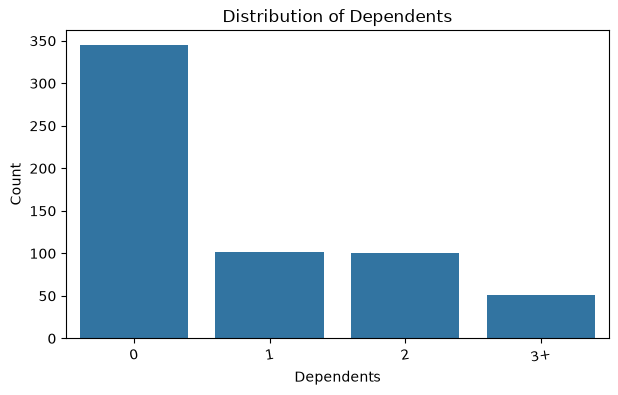

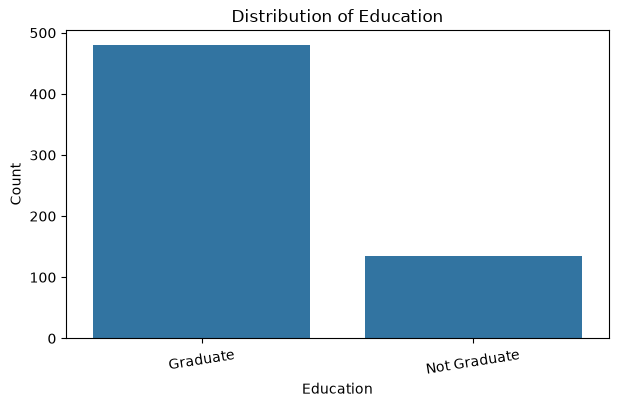

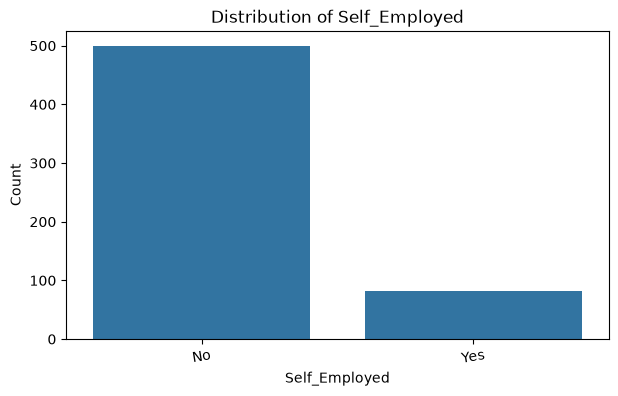

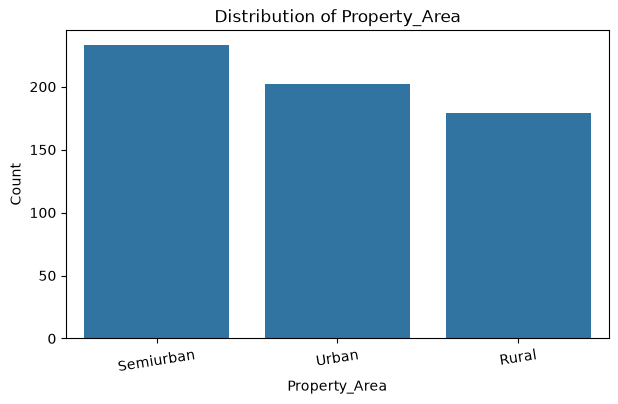

In [15]:
categorical_cols = [
    "Gender",
    "Married",
    "Dependents",
    "Education",
    "Self_Employed",
    "Property_Area"
]

for col in categorical_cols:

    plt.figure(figsize=(7, 4))

    sns.countplot(data=df, x=col, order=df[col].value_counts().index)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")

    plt.xticks(rotation=9)
    plt.show()

# Feature vs Loan status 


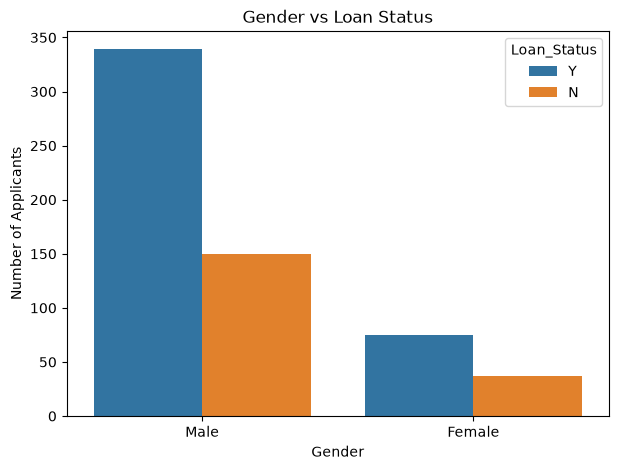

In [16]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Gender",
    hue="Loan_Status"
)

plt.title("Gender vs Loan Status")
plt.xlabel("Gender")
plt.ylabel("Number of Applicants")

plt.show()

# Loan vs married status 

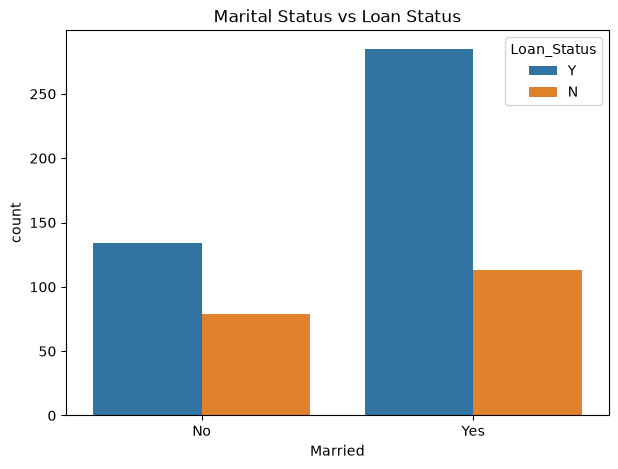

In [17]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Married",
    hue="Loan_Status"
)

plt.title("Marital Status vs Loan Status")
plt.show()

# Education vs Loan status

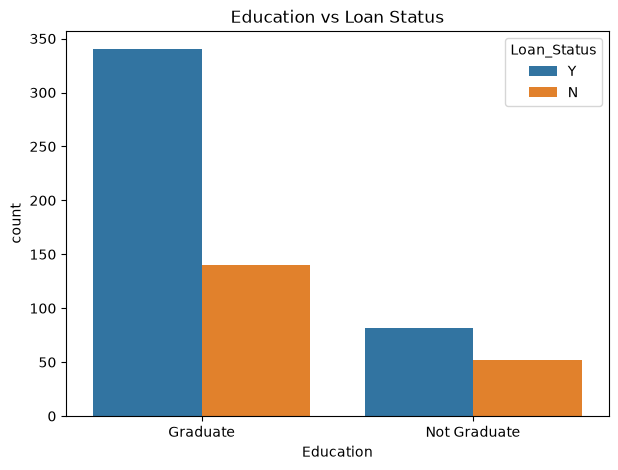

In [18]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Education",
    hue="Loan_Status"
)

plt.title("Education vs Loan Status")
plt.show()

# Self employed vs loan status 

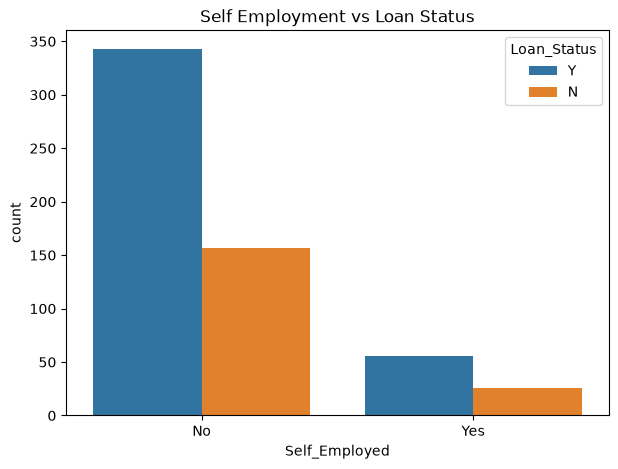

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Self_Employed",
    hue="Loan_Status"
)

plt.title("Self Employment vs Loan Status")
plt.show()

# Property vs loan status 

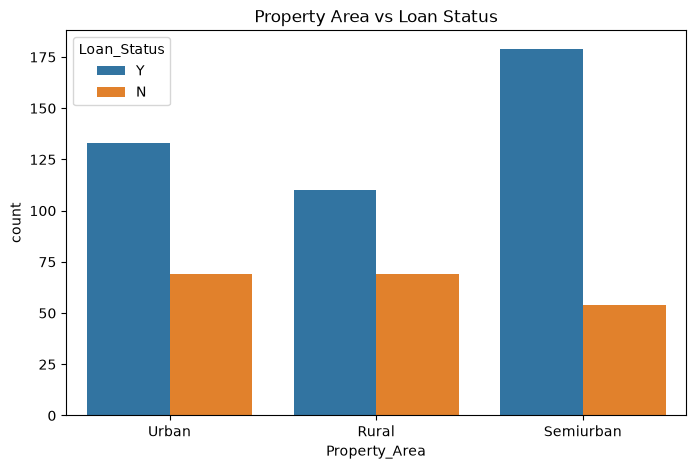

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Property_Area",
    hue="Loan_Status"
)

plt.title("Property Area vs Loan Status")
plt.show()

# Clean Dataset 

In [21]:
df = df.drop('Loan_ID', axis=1)

In [22]:
df.isnull().sum() # checking how many missing values has in dataset 

Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [23]:
# remove the + sign from the value 
df['Dependents'] = df['Dependents'].str.replace(r'\+', '', regex=True).str.strip() # remove the 3+ value from the dataset 

In [24]:
ds = df['Dependents'].unique()
ds

<ArrowStringArray>
['0', '1', '2', '3', nan]
Length: 5, dtype: str

In [25]:
df = df.fillna({'Gender':'Unknown', 'Married':'Unknown','Self_Employed':'Unknown', 'LoanAmount':df['LoanAmount'].median(), 'Loan_Amount_Term':df['Loan_Amount_Term'].median(), 'Credit_History': df['Credit_History'].median(), 'Dependents':'0'}) # replace the missing value with my own value

In [26]:
df.isnull().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [27]:
df['Dependents'] = df['Dependents'].astype(int) # convert into integer


# Feature engineering 

In [28]:
df["TotalIncome"] = (df["ApplicantIncome"] + df["CoapplicantIncome"])

In [29]:
df.columns

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status',
       'TotalIncome'],
      dtype='str')

In [30]:
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,TotalIncome
0,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y,5849.0
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,6091.0
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,3000.0
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,4941.0
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,6000.0


In [31]:
ddd = df['Property_Area'].unique()
print(ddd)

<ArrowStringArray>
['Urban', 'Rural', 'Semiurban']
Length: 3, dtype: str


# Convert numeric - looking object columns 

In [32]:
# Convert Loan_Amount_Term from object/string to numeric
df["Loan_Amount_Term"] = pd.to_numeric(df["Loan_Amount_Term"],errors="coerce")

# Convert Credit_History from object/string to numeric
df["Credit_History"] = pd.to_numeric(df["Credit_History"],errors="coerce")

In [33]:
d = df['Credit_History'].unique()
print(d)

[1. 0.]


# Prepare the Features and target 
`My target is Loan status `

# Separate X and y 

In [34]:
# 1. Drop rows where Loan_Status is missing BEFORE separating X and y
df = df.dropna(subset=["Loan_Status"])

# 2. X contains all input features
X = df.drop("Loan_Status", axis=1)

# 3. y contains only the target column, cleaned of spaces, and mapped safely
y = df["Loan_Status"].astype(str).str.strip().map({'N': 0, 'Y': 1})


In [35]:
dfw = df['Loan_Status'].unique()
print(dfw)

<ArrowStringArray>
['Y', 'N']
Length: 2, dtype: str


# Split into training and testing data

In [36]:
df.isnull().sum()

Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
TotalIncome          0
dtype: int64

In [37]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,                         # Input features
    y,                         # Target
    test_size=0.20,            # 20% → testing data
    random_state=42,           # Reproducible split
    stratify=y                 # Preserve Y/N proportion
)

In [38]:
# Check the shape of each dataset
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (491, 12)
X_test : (123, 12)
y_train: (491,)
y_test : (123,)


In [39]:
df.dtypes

Gender                   str
Married                  str
Dependents             int64
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
Loan_Status              str
TotalIncome          float64
dtype: object

# Categorical and numerical columns

In [40]:
# Categorical columns → need One-Hot Encoding
categorical_features = [
    "Gender",
    "Married",
    "Education",
    "Self_Employed",
    "Property_Area"
]

# Numerical columns → don't need encoding
numeric_features = [
    "Dependents",
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "Credit_History",
    "TotalIncome"
]

In [41]:
df.dtypes

Gender                   str
Married                  str
Dependents             int64
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
Loan_Status              str
TotalIncome          float64
dtype: object

# Numerical Preprocessing 

In [42]:
numeric_pipeline = Pipeline([

    # Fill missing numerical values using median
    ("imputer", SimpleImputer(strategy="median")),

    # Scale numerical features
    ("scaler", StandardScaler())
])

# Categorical Preprocessing 

In [43]:
categorical_pipeline = Pipeline([

    # Fill missing categorical values
    # using the most frequent category
    ("imputer", SimpleImputer(strategy="most_frequent")),

    # ⭐ ENCODING HAPPENS HERE ⭐
    # Convert categorical values into numerical columns
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])


# Combine numerical + Categorical proprocessing 

In [44]:
preprocessor = ColumnTransformer([

    # Numerical columns
    # → Imputation → Scaling
    ("num", numeric_pipeline, numeric_features),

    # Categorical columns
    # → Imputation → One-Hot Encoding
    ("cat", categorical_pipeline, categorical_features)
])


# Create XGBoost model 

In [45]:
xgb_model = XGBClassifier(

    # Number of boosting trees
    n_estimators=200,

    # Contribution of each tree
    learning_rate=0.05,

    # Maximum depth of each tree
    max_depth=3,

    # Use 80% of training rows for each tree
    subsample=0.8,

    # Use 80% of features for each tree
    colsample_bytree=0.8,

    # Binary classification
    objective="binary:logistic",

    # Loss metric
    eval_metric="logloss",

    # Reproducibility
    random_state=42,

    # Use all available CPU cores
    n_jobs=-1
)



# XGBoost Pipeline 

In [46]:
xgb_pipeline = Pipeline([

    # Step 1:
    # Imputation + Encoding + Scaling
    ("preprocessor", preprocessor),

    # Step 2:
    # XGBoost
    ("model", xgb_model)
])

In [47]:
xgb_pipeline.fit(
    X_train,
    y_train
)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Gender','Married','Dependents',...,'Credit_History','Property_Area', 'TotalIncome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passth

# Make Predictions 

In [48]:
y_pred = xgb_pipeline.predict(X_test)


# Get Prediction probabilities 

In [49]:
# Probability of class 1 = Approved
y_prob = xgb_pipeline.predict_proba(X_test)[:, 1]

# Evaluate Model 

In [50]:
from xgboost import XGBClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [51]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)



# Display the results

In [52]:
print("=" * 45)
print("           XGBOOST RESULTS")
print("=" * 45)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

           XGBOOST RESULTS
Accuracy  : 0.8293
Precision : 0.8333
Recall    : 0.9412
F1 Score  : 0.8840
ROC-AUC   : 0.8217


# Classification Report


In [53]:

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Rejected","Approved"]))




Classification Report:
              precision    recall  f1-score   support

    Rejected       0.81      0.58      0.68        38
    Approved       0.83      0.94      0.88        85

    accuracy                           0.83       123
   macro avg       0.82      0.76      0.78       123
weighted avg       0.83      0.83      0.82       123



# Confusion matrix 

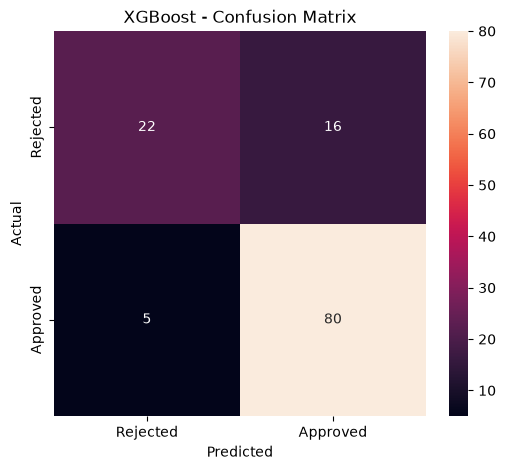

In [54]:

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Rejected",
        "Approved"
    ],
    yticklabels=[
        "Rejected",
        "Approved"
    ]
)

plt.title("XGBoost - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()


# Hyperparameter tuning 

In [55]:
from sklearn.model_selection import RandomizedSearchCV
param_grid = {

    # Number of trees
    "model__n_estimators": [
        100,
        200,
        300,
        500
    ],

    # Learning rate
    "model__learning_rate": [
        0.01,
        0.03,
        0.05,
        0.1
    ],

    # Tree depth
    "model__max_depth": [
        2,
        3,
        4,
        5
    ],

    # Minimum child weight
    "model__min_child_weight": [
        1,
        3,
        5
    ],

    # Row sampling
    "model__subsample": [
        0.7,
        0.8,
        0.9,
        1.0
    ],

    # Feature sampling
    "model__colsample_bytree": [
        0.7,
        0.8,
        0.9,
        1.0
    ],

    # Minimum loss reduction
    "model__gamma": [
        0,
        0.1,
        0.3,
        0.5
    ],

    # L1 regularization
    "model__reg_alpha": [
        0,
        0.01,
        0.1,
        1
    ],

    # L2 regularization
    "model__reg_lambda": [
        1,
        2,
        5
    ]
}

# Randomized search 

In [56]:
random_search = RandomizedSearchCV(

    # Complete preprocessing + XGBoost pipeline
    estimator=xgb_pipeline,

    # Hyperparameter combinations
    param_distributions=param_grid,

    # Number of combinations to test
    n_iter=30,

    # 5-fold cross-validation
    cv=5,

    # Optimize F1 Score
    scoring="f1",

    # Use all CPU cores
    n_jobs=-1,

    # Reproducibility
    random_state=42,

    # Show progress
    verbose=1
)


# Train Randomized search 

In [57]:
random_search.fit(
    X_train,
    y_train
)


Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': [0.7, 0.8, ...], 'model__gamma': [0, 0.1, ...], 'model__learning_rate': [0.01, 0.03, ...], 'model__max_depth': [2, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set 

# Best parameters 

In [58]:
print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(random_search.best_score_)


Best Parameters:
{'model__subsample': 1.0, 'model__reg_lambda': 5, 'model__reg_alpha': 0.01, 'model__n_estimators': 100, 'model__min_child_weight': 5, 'model__max_depth': 5, 'model__learning_rate': 0.03, 'model__gamma': 0.3, 'model__colsample_bytree': 0.8}

Best Cross-Validation F1 Score:
0.8707669133878717


# Fine Tune Model 

In [59]:
final_model = random_search.best_estimator_

# Final Test Prediction 

In [60]:
final_pred = final_model.predict(
    X_test
)

final_prob = final_model.predict_proba(
    X_test
)[:, 1]

# Final Model Evaluation

In [61]:
final_accuracy = accuracy_score(
    y_test,
    final_pred
)

final_precision = precision_score(
    y_test,
    final_pred
)

final_recall = recall_score(
    y_test,
    final_pred
)

final_f1 = f1_score(
    y_test,
    final_pred
)

final_roc_auc = roc_auc_score(
    y_test,
    final_prob
)


print("\n" + "=" * 45)
print("          FINAL XGBOOST RESULTS")
print("=" * 45)

print(f"Accuracy  : {final_accuracy:.4f}")
print(f"Precision : {final_precision:.4f}")
print(f"Recall    : {final_recall:.4f}")
print(f"F1 Score  : {final_f1:.4f}")
print(f"ROC-AUC   : {final_roc_auc:.4f}")


          FINAL XGBOOST RESULTS
Accuracy  : 0.8537
Precision : 0.8317
Recall    : 0.9882
F1 Score  : 0.9032
ROC-AUC   : 0.7924


# Final Classification report 

In [62]:
print("\nFinal Classification Report:")

print(
    classification_report(
        y_test,
        final_pred,
        target_names=[
            "Rejected",
            "Approved"
        ]
    )
)



Final Classification Report:
              precision    recall  f1-score   support

    Rejected       0.95      0.55      0.70        38
    Approved       0.83      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.77      0.80       123
weighted avg       0.87      0.85      0.84       123



# Final Confusion Matrix 

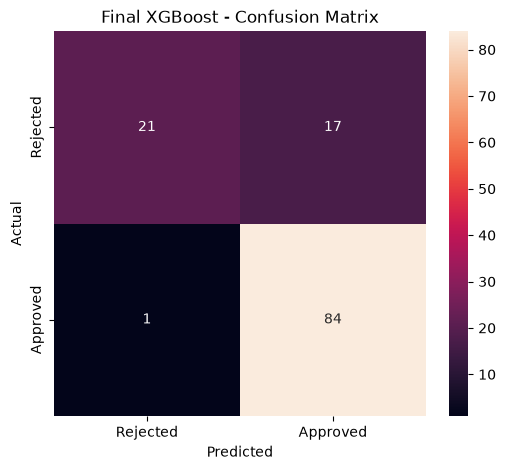

In [63]:
# ============================================================
# 28. FINAL CONFUSION MATRIX
# ============================================================

final_cm = confusion_matrix(
    y_test,
    final_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Rejected",
        "Approved"
    ],
    yticklabels=[
        "Rejected",
        "Approved"
    ]
)

plt.title("Final XGBoost - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

# Feature importance 

Because you used a Pipeline + OneHotEncoder, we need to correctly extract the feature names and XGBoost importance.

In [64]:
# Get the trained XGBoost model from the pipeline
xgb_final = final_model.named_steps["model"]

# Get the fitted preprocessor
fitted_preprocessor = final_model.named_steps["preprocessor"]

# Get feature names after encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# Get XGBoost feature importance
importance = xgb_final.feature_importances_

# Create a DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort from highest to lowest importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_df.head(15))

                         Feature  Importance
5            num__Credit_History    0.541919
19  cat__Property_Area_Semiurban    0.053436
2         num__CoapplicantIncome    0.047621
14   cat__Education_Not Graduate    0.042663
13       cat__Education_Graduate    0.037104
6               num__TotalIncome    0.036897
0                num__Dependents    0.036377
3                num__LoanAmount    0.033726
1           num__ApplicantIncome    0.033585
20      cat__Property_Area_Urban    0.033551
18      cat__Property_Area_Rural    0.031382
10               cat__Married_No    0.031122
7             cat__Gender_Female    0.022938
12              cat__Married_Yes    0.010802
8               cat__Gender_Male    0.006877


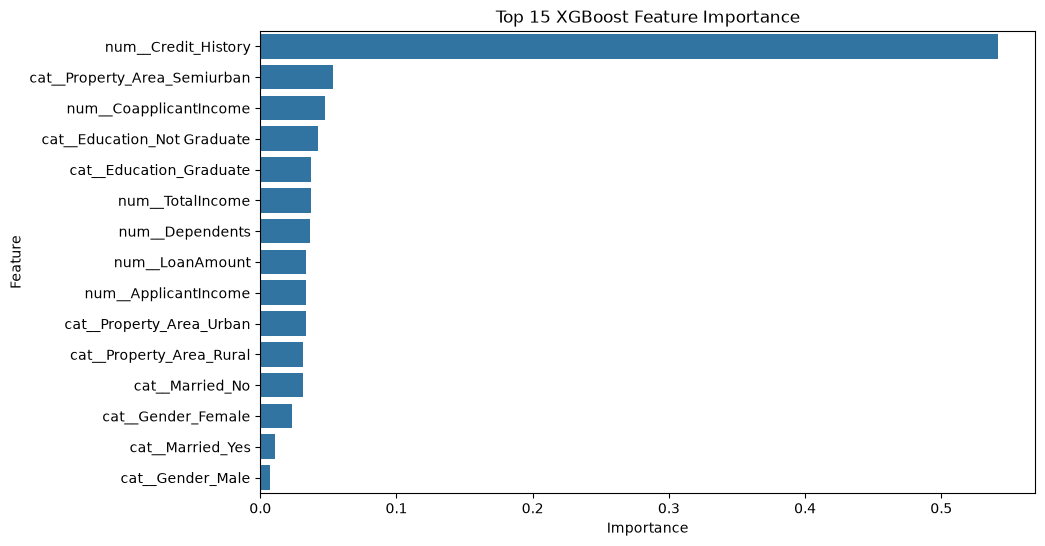

In [65]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 XGBoost Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

# Save the model 


In [66]:
import pickle as pk 
import joblib

# Save the complete trained XGBoost pipeline
joblib.dump(final_model,"loan_xgboost_model_1.pkl")

['loan_xgboost_model_1.pkl']

In [67]:
print(X_train.columns.tolist())

['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'TotalIncome']


In [68]:
print(X_train.dtypes)

Gender                   str
Married                  str
Dependents             int64
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
TotalIncome          float64
dtype: object


In [69]:
print(y.unique())

[1 0]


In [70]:
print(final_model.predict(X_test.head(5)))
print(final_model.predict_proba(X_test.head(5)))

[0 1 1 1 1]
[[0.83613634 0.16386369]
 [0.37653446 0.62346554]
 [0.2627324  0.7372676 ]
 [0.31338775 0.68661225]
 [0.1405074  0.8594926 ]]


In [71]:
print("COLUMNS:")
print(X_train.columns.tolist())

print("\nDTYPES:")
print(X_train.dtypes)

print("\nTARGET:")
print(y.unique())

print("\nMODEL TEST:")
print(final_model.predict(X_test.head(5)))
print(final_model.predict_proba(X_test.head(5)))

COLUMNS:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'TotalIncome']

DTYPES:
Gender                   str
Married                  str
Dependents             int64
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
TotalIncome          float64
dtype: object

TARGET:
[1 0]

MODEL TEST:
[0 1 1 1 1]
[[0.83613634 0.16386369]
 [0.37653446 0.62346554]
 [0.2627324  0.7372676 ]
 [0.31338775 0.68661225]
 [0.1405074  0.8594926 ]]


In [72]:
! pip freeze > requirements.txt